# Lab 07: Compression - pruning and distillation

## 1. Oversized baseline CNN
Train a 1,018,858-parameter CNN for five epochs on Fashion-MNIST. Use 55,000 training, 5,000 validation and the official 10,000 test images; seed 42, Adam lr=0.001, batch 512, normalized float32 inputs and CPU with two threads. The model uses Conv(1,8), Conv(8,16), pooling after each convolution, and Linear(784,1280)-ReLU-Linear(1280,10). Record final accuracy, parameters, serialized size and inference latency.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd()/'src'/'experiment.py').exists() else Path.cwd()/'lab07'
sys.path.insert(0,str(ROOT.parent))
from lab07.src.experiment import Experiment
experiment = Experiment(ROOT)
baseline = experiment.baseline()
print(baseline.to_string(index=False))


C:\Users\maria\Desktop\university\ML_73952\lab01\.venv\Lib\site-packages\torch\cuda\__init__.py:56: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
Loaded recorded teacher checkpoint and measurements.
variant   method  requested_weight_sparsity  measured_weight_sparsity  requested_filter_fraction  parameters  nonzero_weights  test_accuracy  test_loss  dense_bytes  csr_bytes  batch1_median_ms  batch128_median_ms  dense_matmul_flops  ideal_nonzero_flops  inference_cpu_ms_per_image  data_train_rows  data_test_rows  energy_joules                       energy_measurement    dense_artifact           csr_artifact  training_wall_seconds  training_cpu_seconds mask_fixed_verified reused_control kept_conv1 kept_conv2  actual_filter_fraction_removed                                                   

## 2. Magnitude and structured pruning
Start each variant from the same original teacher. Rank conv/linear weights by magnitude, excluding biases. Apply global and per-layer masks at sparsities 0, 0.25, 0.5, 0.75, 0.9 and 0.95. Fine-tune each for three epochs with fixed masks, Adam lr=0.0001. The 0% global and layer-wise procedures are identical and share one trained control, explicitly identified in the table.

Structured pruning ranks convolutional output filters by L2 norm and physically removes 10%, 25% or 50% (rounded to integer channel counts). Dependent convolution input channels and flattened FC columns are removed as well. An equivalence check compares the compact model with matching channel gates before three fine-tuning epochs.


Loaded recorded global_00 measurements.
Loaded recorded global_25 measurements.
Loaded recorded global_50 measurements.
Loaded recorded global_75 measurements.
Loaded recorded global_90 measurements.
Loaded recorded global_95 measurements.
Loaded recorded layerwise_00 measurements.
Loaded recorded layerwise_25 measurements.
Loaded recorded layerwise_50 measurements.
Loaded recorded layerwise_75 measurements.
Loaded recorded layerwise_90 measurements.
Loaded recorded layerwise_95 measurements.
Loaded recorded structured_10 measurements.
Loaded recorded structured_25 measurements.
Loaded recorded structured_50 measurements.
      variant  measured_weight_sparsity  requested_filter_fraction  parameters  test_accuracy
      teacher                  0.000000                       0.00     1018858         0.8737
    global_00                  0.000000                       0.00     1018858         0.8872
    global_25                  0.250000                       0.00     1018858         0

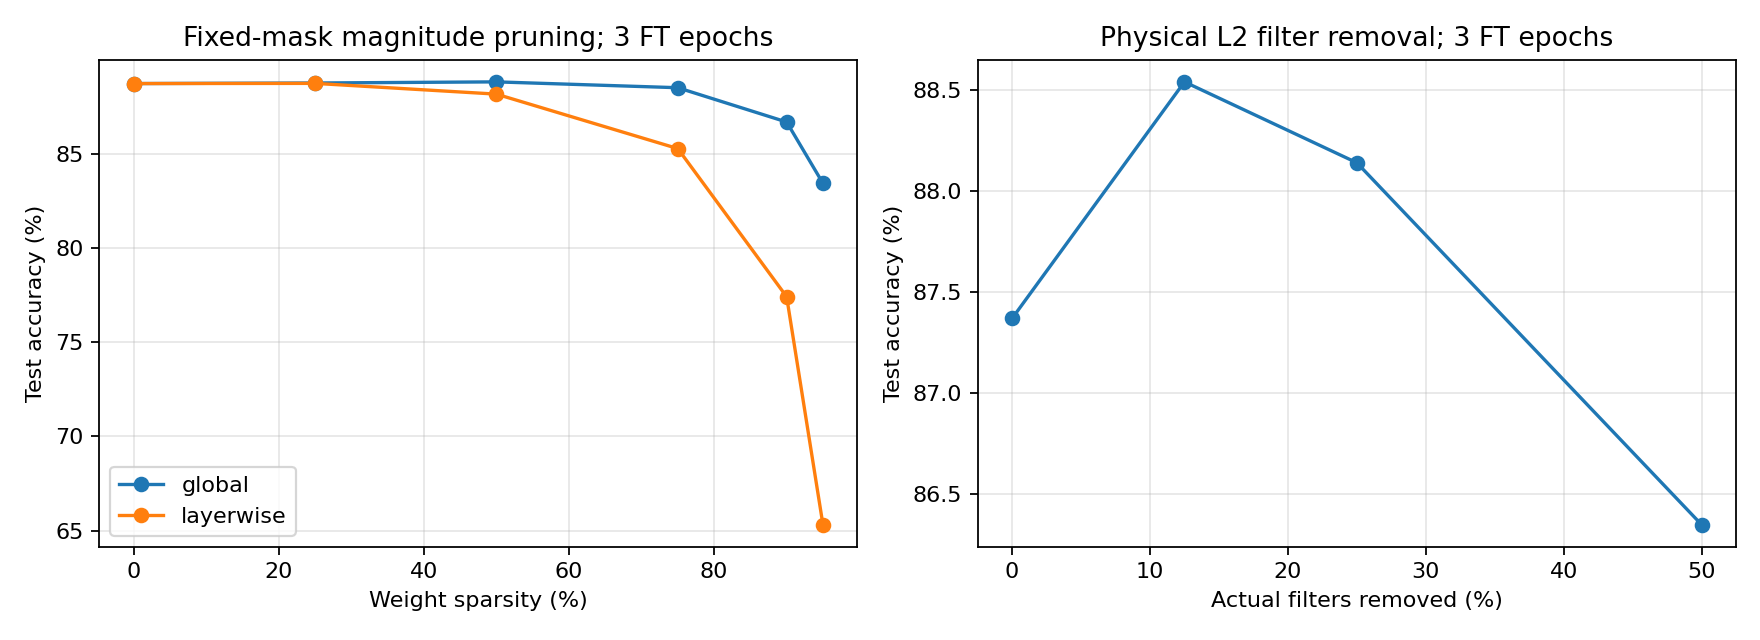

In [2]:
pruning_table = experiment.pruning()
print(pruning_table[['variant','measured_weight_sparsity','requested_filter_fraction','parameters','test_accuracy']].to_string(index=False))
try:
    from IPython.display import Image, display
except ImportError:
    print('Plot saved:', experiment.out/'sparsity_curves.png')
else:
    display(Image(filename=str(experiment.out/'sparsity_curves.png')))


## 3. Latency and dense versus sparse storage
Compare actual dense checkpoint bytes with an uncompressed CSR NumPy archive containing values, indices, row pointers, tensor shapes, biases and architecture metadata. Sparse archives are reconstructed and all tensors checked for equality. Sparse storage is not a sparse execution backend: inference remains ordinary dense PyTorch. Batch-1 latency is the median of 100 runs after 20 warm-ups; batch 128 uses 20 runs after five warm-ups. Inputs are prepared tensors and device/data-loading time is excluded.

Final latency results in section 5 use three post-training rounds with models measured in shuffled order. The initial per-variant measurements are also retained.


      variant  parameters  dense_bytes  csr_bytes  batch1_median_ms  dense_matmul_flops
      teacher     1018858      4078080    8156854           2.08435             2597120
    global_00     1018858      4078424    8156854           1.24310             2597120
    global_25     1018858      4078424    6121766           1.05515             2597120
    global_50     1018858      4078424    4086678           1.37965             2597120
    global_75     1018858      4078424    2051590           1.53280             2597120
    global_90     1018858      4078424     830534           1.20210             2597120
    global_95     1018858      4078424     423518           0.95790             2597120
 layerwise_00     1018858      4078424    8156854           1.24310             2597120
 layerwise_25     1018858      4078460    6121766           1.34035             2597120
 layerwise_50     1018858      4078460    4086678           1.03485             2597120
 layerwise_75     1018858      4

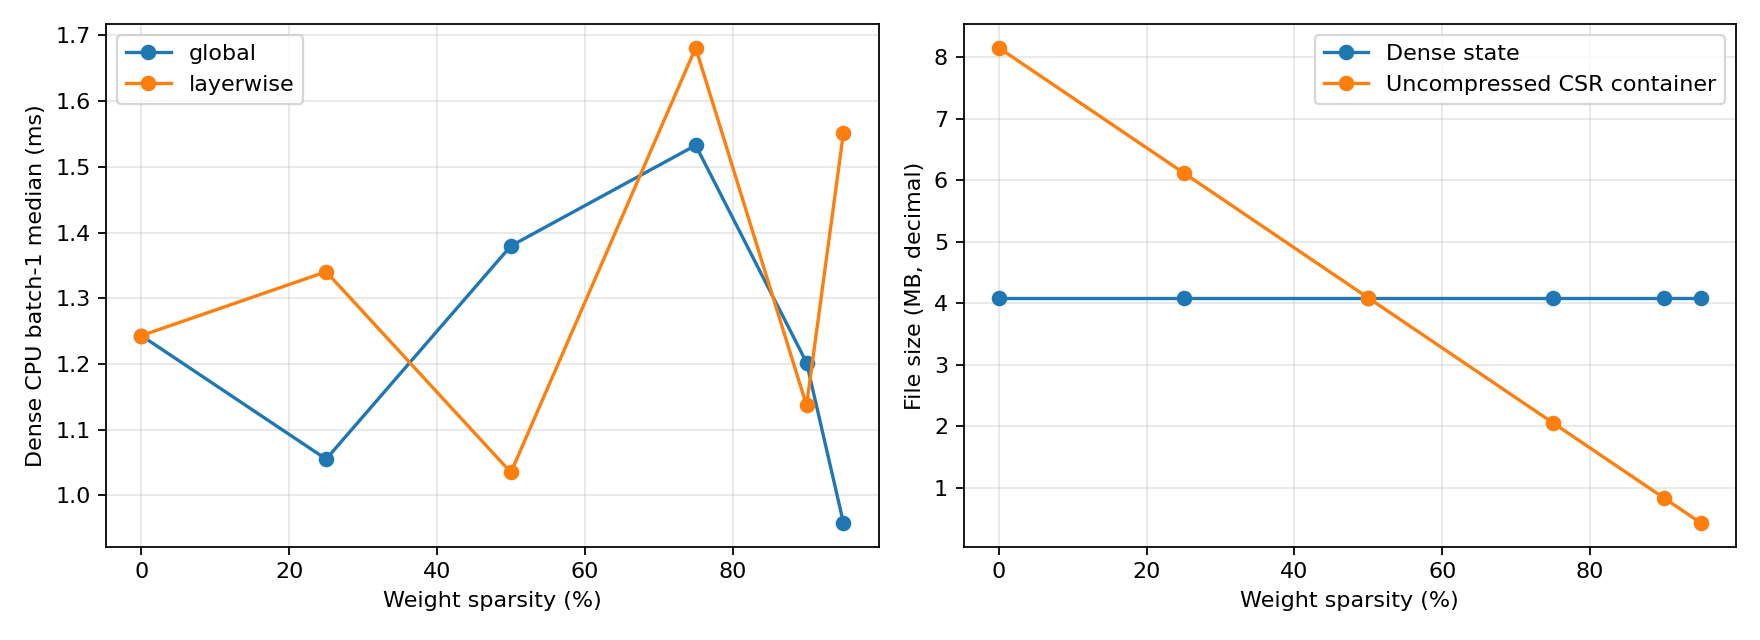

In [3]:
storage_table = experiment.storage_latency()
print(storage_table.to_string(index=False))
if 'display' in globals():
    display(Image(filename=str(experiment.out/'storage_latency.png')))
else:
    print('Plot saved:', experiment.out/'storage_latency.png')


## 4. Knowledge distillation
Teacher: the original unpruned CNN. Student: the same convolutional blocks with FC hidden width 128 (103,018 parameters). Train a plain student and a distilled student for five epochs each using identical initialization, batches and Adam lr=0.001. Use T=4 and alpha=0.5.

The exact manual loss is 0.5*CE + 0.5*T**2*KL(student_softmax || teacher_softmax). Compute sum(p_student*(log_p_student-log_p_teacher)) averaged over the batch. Teacher probabilities are detached and the teacher remains frozen in eval mode. This is the student-to-teacher KL direction written in the manual.


In [4]:
distillation_table = experiment.distillation()
print(distillation_table[['variant','parameters','test_accuracy','dense_bytes','csr_bytes','batch1_median_ms','training_wall_seconds']].to_string(index=False))


Loaded recorded student_plain measurements.
Loaded recorded student_distilled measurements.
          variant  parameters  test_accuracy  dense_bytes  csr_bytes  batch1_median_ms  training_wall_seconds
          teacher     1018858         0.8737      4078080    8156854           2.08435             125.949295
    student_plain      103018         0.8561       415112     830134           0.73350              53.839830
student_distilled      103018         0.8577       415160     830134           1.30830             110.749988


## 5. Efficiency pillars and conclusion
Data: all models use the same dataset and split. Model: compare parameter/nonzero counts and actual storage. Compute: compare product FLOPs, measured latency and training time. Energy: hardware Joules are unavailable; report process CPU time as an energy-related activity proxy, not an energy measurement. It cannot establish energy savings without power measurements.

Unstructured zeros preserve tensor shapes, so dense kernels still compute full matrix products; ideal nonzero FLOPs are an upper-bound opportunity, not executed FLOPs. Physical filter removal and a smaller student can reduce actual dense compute. CSR storage can be larger at low sparsity because indices add overhead.

Final latency is the median of three interleaved rounds (same warm-ups and repetitions per round), after all training has finished. Initial measurements and all round results are saved separately.


Using recorded interleaved latency checks.
          variant  data_train_rows  data_test_rows  test_accuracy  parameters  nonzero_weights  dense_bytes  csr_bytes  dense_matmul_flops  batch1_median_ms  training_wall_seconds  training_cpu_seconds  inference_cpu_ms_per_image  energy_joules
          teacher            55000           10000         0.8737     1018858          1017544      4078080    8156854             2597120           2.08435             125.949295            279.500000                     3.59375            NaN
        global_00            55000           10000         0.8872     1018858          1017544      4078424    8156854             2597120           1.24310              78.181752            167.781250                     3.28125            NaN
        global_25            55000           10000         0.8875     1018858           763158      4078424    6121766             2597120           1.05515              73.437764            160.859375                     

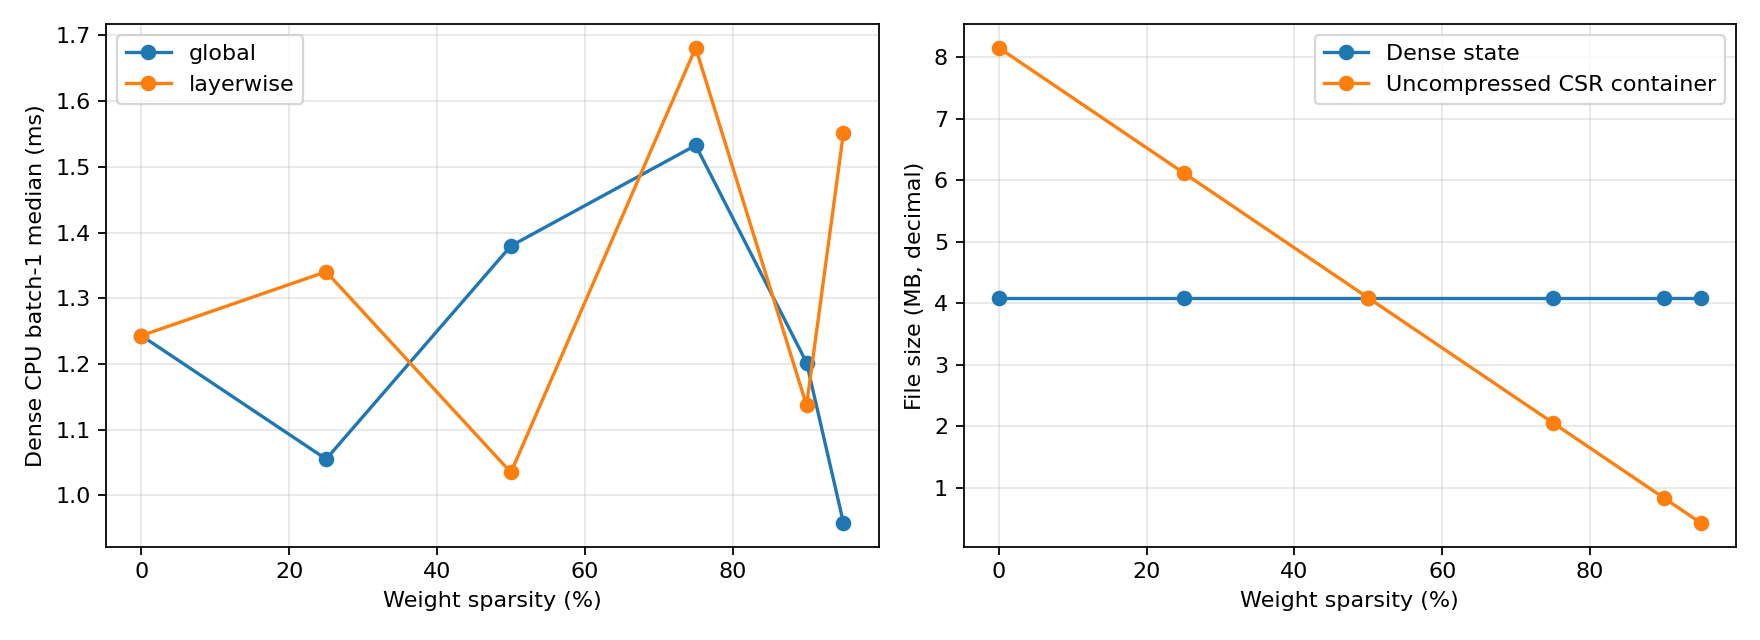

In [5]:
from lab07.src.latency import interleaved_latency
interleaved_latency(experiment)
experiment.storage_latency()
summary = experiment.summary()
print(summary.to_string(index=False))
teacher_acc = float(summary.loc[summary.variant=='teacher','test_accuracy'].iloc[0])
plain_acc = float(summary.loc[summary.variant=='student_plain','test_accuracy'].iloc[0])
kd_acc = float(summary.loc[summary.variant=='student_distilled','test_accuracy'].iloc[0])
print(f'Teacher accuracy: {teacher_acc:.2%}; plain student: {plain_acc:.2%}; distilled student: {kd_acc:.2%}.')
print(f'Distillation change versus plain student: {100*(kd_acc-plain_acc):+.2f} percentage points.')
print('Energy in Joules was not measured; CPU-time columns are proxies only.')

from lab07.src.report import build_report
build_report(ROOT)
